# TP1 : Apprentissage supervisé avec Scikit-learn
**Module** : Technologies IA, ENSA Fès, ILIA 2
**Professeur** : Youness IDRISSI KHAMLICHI
**Étudiantes** : RIFKI Chaymae, Imane OUBOUNI

## Plan
1. Exercice 1 : Régression, prédiction du tarif d'un trajet Uber
2. Exercice 2 : Classification, survie sur le Titanic
3. Mini-projet : Prédiction de maladie cardiaque (comparaison de 4 modèles) + conclusion critique

### Fichiers de données attendus
| Fichier | Où le mettre |
|---|---|
| `data/heartdiseases.csv` | déjà dans le repo |
| `data/titanic.csv` (= `train.csv` de Kaggle renommé) | dossier `data/` |
| `data_locale/uber.csv` | dossier `data_locale/` (trop lourd pour GitHub, **non envoyé** ; lien Kaggle dans le README) |

## 0. Imports communs
On importe une seule fois toutes les bibliothèques utilisées dans le notebook.

In [1]:
import warnings
warnings.filterwarnings('ignore')   # cache les avertissements non importants

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, classification_report, confusion_matrix)

sns.set_style('whitegrid')

# Exercice 1 : Régression, prédiction du tarif Uber
**Objectif** : prédire `fare_amount` (le prix en $) à partir de la distance, de l'heure et du jour de la semaine.
**Type de problème** : régression (la sortie est une valeur numérique continue).

## Étape 1 : Chargement et exploration

In [2]:
data = pd.read_csv('data_locale/uber.csv')

print(data.head())            # 5 premières lignes
print(data.info())            # types des colonnes
print(data.isnull().sum())    # valeurs manquantes par colonne
print(data.describe())        # min / max / moyenne : sert à repérer les valeurs aberrantes

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

**Observations** *(à compléter avec tes résultats)* :
- Nombre de lignes et de colonnes : ...
- Colonnes utiles : `fare_amount`, `pickup_datetime`, coordonnées GPS, `passenger_count`
- Valeurs manquantes : ...
- Valeurs aberrantes visibles dans `describe()` (tarifs négatifs, coordonnées à 0, etc.) : ...

## Étape 2 : Nettoyage et préparation
- On supprime les valeurs manquantes et les valeurs aberrantes.
- On crée des variables dérivées : `hour`, `day_of_week`.
- **Important** : le dataset ne contient pas de colonne `distance`. On la calcule avec la **formule de Haversine** (distance entre deux points GPS, en km).

In [3]:
# 1. Valeurs manquantes
data = data.dropna()

# 2. Valeurs aberrantes
data = data[(data['fare_amount'] > 0) & (data['fare_amount'] < 200)]
data = data[(data['passenger_count'] > 0) & (data['passenger_count'] <= 6)]
# Coordonnées valides (zone de New York)
data = data[data['pickup_latitude'].between(40, 42) & data['dropoff_latitude'].between(40, 42)]
data = data[data['pickup_longitude'].between(-75, -72) & data['dropoff_longitude'].between(-75, -72)]

# 3. Variables dérivées de la date
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek   # 0 = lundi ... 6 = dimanche

# 4. Distance (Haversine) en km
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # rayon de la Terre en km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

data['distance'] = haversine(data['pickup_latitude'], data['pickup_longitude'],
                             data['dropoff_latitude'], data['dropoff_longitude'])
data = data[(data['distance'] > 0) & (data['distance'] < 100)]

print('Taille après nettoyage :', data.shape)

Taille après nettoyage : (193055, 12)


**Justification du nettoyage** *(à compléter)* : combien de lignes supprimées ? Pourquoi ces seuils (tarif < 200 $, distance < 100 km, coordonnées dans New York) ?

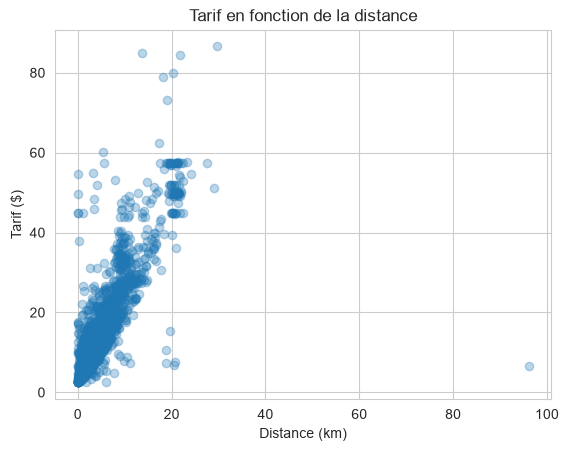

In [4]:
# Relation distance / tarif (échantillon de 5000 points pour un graphique lisible)
sample = data.sample(5000, random_state=42)
plt.scatter(sample['distance'], sample['fare_amount'], alpha=0.3)
plt.xlabel('Distance (km)')
plt.ylabel('Tarif ($)')
plt.title('Tarif en fonction de la distance')
plt.show()

## Étape 3 : Séparation train / test
80 % des données pour l'entraînement, 20 % pour le test. `random_state=42` rend les résultats reproductibles.

In [5]:
X = data[['distance', 'hour', 'day_of_week']]   # features (entrées)
y = data['fare_amount']                          # target (ce qu'on prédit)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train :', X_train.shape, '| Test :', X_test.shape)

Train : (154444, 3) | Test : (38611, 3)


## Étapes 4 et 5 : Régression linéaire et évaluation
Métriques : **MAE** (erreur moyenne en $), **RMSE** (pénalise les grosses erreurs), **R²** (1 = parfait, 0 = pas mieux que la moyenne).

In [6]:
lr = LinearRegression()
lr.fit(X_train, y_train)          # le modèle apprend les coefficients
y_pred = lr.predict(X_test)       # prédictions sur des données jamais vues

mae_lr = mean_absolute_error(y_test, y_pred)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred))
r2_lr = r2_score(y_test, y_pred)
print('MAE  =', round(mae_lr, 3))
print('RMSE =', round(rmse_lr, 3))
print('R²   =', round(r2_lr, 3))

# Coefficients appris (utiles pour l'interprétation)
for nom, coef in zip(X.columns, lr.coef_):
    print(f'{nom:12s} -> {coef:.4f}')
print('Intercept   ->', round(lr.intercept_, 4))

MAE  = 2.388
RMSE = 5.347
R²   = 0.689
distance     -> 2.2177
hour         -> 0.0074
day_of_week  -> -0.0360
Intercept   -> 3.9086


## Étapes 6 et 7 : Amélioration avec Random Forest et visualisation

In [7]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

comparaison = pd.DataFrame({
    'Modèle': ['Régression linéaire', 'Random Forest'],
    'MAE': [mae_lr, mae_rf],
    'RMSE': [rmse_lr, rmse_rf],
    'R²': [r2_lr, r2_rf]
}).round(3)
print(comparaison)

                Modèle    MAE   RMSE     R²
0  Régression linéaire  2.388  5.347  0.689
1        Random Forest  2.494  4.765  0.753


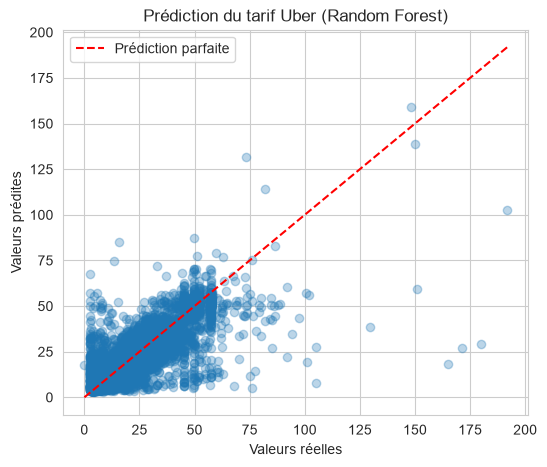

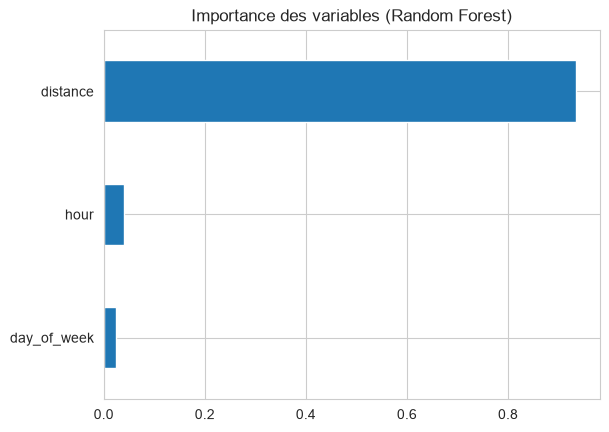

In [8]:
# Valeurs réelles vs prédites : plus les points sont proches de la diagonale rouge, meilleur est le modèle
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_rf, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Prédiction parfaite')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Prédiction du tarif Uber (Random Forest)')
plt.legend()
plt.show()

# Importance des variables
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot(
    kind='barh', title='Importance des variables (Random Forest)')
plt.show()

### Interprétation Exercice 1 *(à compléter avec tes chiffres)*
- Quel modèle a le plus petit MAE / RMSE et le plus grand R² ? ...
- Que représente le coefficient de `distance` (dollars par km) ? ...
- Quelle variable est la plus importante pour le Random Forest ? ...
- Pourquoi le Random Forest fait mieux (ou pas) que la régression linéaire ? (relations non linéaires, interactions heure/distance...) ...

# Exercice 2 : Classification, survie sur le Titanic
**Objectif** : prédire `Survived` (1 = a survécu, 0 = non).
**Type de problème** : classification binaire.

## Étape 1 : Chargement et exploration

In [9]:
data = pd.read_csv('data/titanic.csv')

print(data.head())
print(data.info())
print(data.isnull().sum())     # Age et Cabin ont beaucoup de valeurs manquantes
print(data['Survived'].value_counts())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

## Étape 2 : Nettoyage et traitement
- On garde 8 colonnes utiles.
- `Age` manquant remplacé par la **médiane** (robuste aux valeurs extrêmes).
- `Embarked` manquant remplacé par la **valeur la plus fréquente** (mode).

In [10]:
data = data[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])
print(data.isnull().sum())

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


## Étape 3 : Encodage des variables catégorielles
Les modèles ne comprennent que des nombres : `Sex` (female/male) et `Embarked` (C/Q/S) sont convertis en entiers.

In [11]:
le_sex = LabelEncoder()
le_emb = LabelEncoder()
data['Sex'] = le_sex.fit_transform(data['Sex'])            # female = 0, male = 1
data['Embarked'] = le_emb.fit_transform(data['Embarked'])  # C = 0, Q = 1, S = 2
print(data.head())

   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0         0       3    1  22.0      1      0   7.2500         2
1         1       1    0  38.0      1      0  71.2833         0
2         1       3    0  26.0      0      0   7.9250         2
3         1       1    0  35.0      1      0  53.1000         2
4         0       3    1  35.0      0      0   8.0500         2


## Étape 4 : Séparation train / test

In [12]:
X = data.drop('Survived', axis=1)
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train :', X_train.shape, '| Test :', X_test.shape)

Train : (712, 7) | Test : (179, 7)


## Étape 5 : Entraînement des modèles

In [13]:
log_model = LogisticRegression(max_iter=1000)   # max_iter=1000 évite le ConvergenceWarning
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

## Étape 6 : Évaluation des modèles

In [14]:
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print('Accuracy (Logistic)     :', round(accuracy_score(y_test, y_pred_log), 3))
print('Accuracy (Random Forest):', round(accuracy_score(y_test, y_pred_rf), 3))
print()
print('--- Rapport Random Forest ---')
print(classification_report(y_test, y_pred_rf))
print('--- Rapport Régression logistique ---')
print(classification_report(y_test, y_pred_log))

Accuracy (Logistic)     : 0.81
Accuracy (Random Forest): 0.821

--- Rapport Random Forest ---
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179

--- Rapport Régression logistique ---
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



## Étape 7 : Matrice de confusion

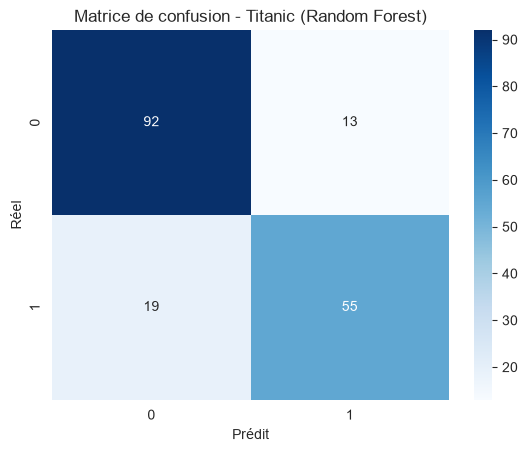

In [15]:
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion - Titanic (Random Forest)')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()

### Interprétation Exercice 2 *(à compléter)*
- Quel modèle a la meilleure accuracy ? Les écarts sont-ils significatifs ? ...
- Lecture de la matrice : combien de vrais positifs (TP), vrais négatifs (TN), faux positifs (FP), faux négatifs (FN) ? ...
- Précision, rappel, F1 pour la classe « survécu » : ...
- Quelle erreur est la plus grave ici (FP ou FN) ? ...

# Partie 2 : Mini-projet : prédiction de maladie cardiaque
**Dataset** : `data/heartdiseases.csv` (50 patients).
**Variables** : Age, Gender, Education, Income, Smoker, Cholesterol.
**Cible** : `Heart_Disease` (Yes / No).
**Type de problème** : classification binaire.

**Démarche** : prétraitement → séparation → comparaison de 4 modèles (test simple **et** validation croisée) → interprétation → conclusion critique.

## 1. Chargement et exploration

In [16]:
heart = pd.read_csv('data/heartdiseases.csv')

print(heart.head())
print(heart.info())
print('Valeurs manquantes :', heart.isnull().sum().sum())
print(heart['Heart_Disease'].value_counts())     # 27 No / 23 Yes : classes assez équilibrées
print(heart.describe())

   Age  Gender            Education  Income Smoker  Cholesterol Heart_Disease
0   42  Female    Bachelor's Degree   65000     No          180            No
1   55    Male  High School Diploma   40000    Yes          245           Yes
2   30  Female      Master's Degree   80000    Yes          210            No
3   39    Male         Some College   50000    Yes          195            No
4   27    Male         Some College   30000     No          170            No
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Age            50 non-null     int64
 1   Gender         50 non-null     str  
 2   Education      50 non-null     str  
 3   Income         50 non-null     int64
 4   Smoker         50 non-null     str  
 5   Cholesterol    50 non-null     int64
 6   Heart_Disease  50 non-null     str  
dtypes: int64(3), str(4)
memory usage: 2.9 KB
None
Valeurs manq

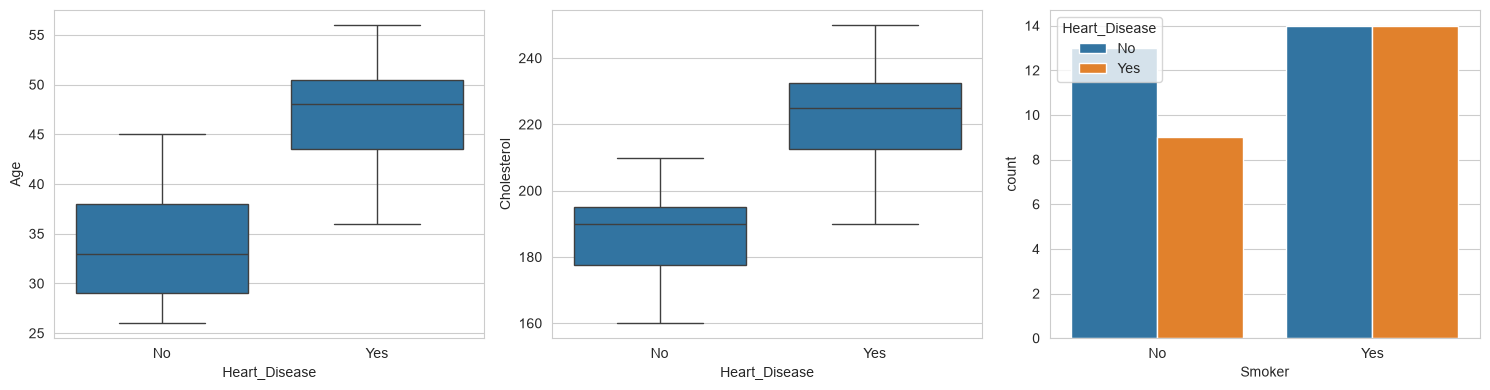

In [17]:
# Exploration visuelle
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=heart, x='Heart_Disease', y='Age', ax=axes[0])
sns.boxplot(data=heart, x='Heart_Disease', y='Cholesterol', ax=axes[1])
sns.countplot(data=heart, x='Smoker', hue='Heart_Disease', ax=axes[2])
plt.tight_layout()
plt.show()

## 2. Prétraitement (25 % de la note)
Choix à justifier :
- **Cible** `Yes/No` convertie en `1/0`.
- **Variables catégorielles** (`Gender`, `Education`, `Smoker`) : *one-hot encoding* (`get_dummies`, `drop_first=True` pour éviter la redondance). On évite `LabelEncoder` pour `Education` car cela inventerait un ordre artificiel entre les niveaux.
- **Standardisation** (`StandardScaler`) pour la régression logistique et le KNN, sensibles à l'échelle (`Income` ~ 50 000 contre `Age` ~ 40). Elle est placée dans un `Pipeline` : le scaler apprend uniquement sur les données d'entraînement, ce qui évite la **fuite de données**.
- **`stratify=y`** pour garder la même proportion de Yes/No dans train et test.

In [18]:
df = heart.copy()
df['Heart_Disease'] = df['Heart_Disease'].map({'No': 0, 'Yes': 1})
df = pd.get_dummies(df, columns=['Gender', 'Education', 'Smoker'], drop_first=True, dtype=int)
print(df.head())

X = df.drop('Heart_Disease', axis=1)
y = df['Heart_Disease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print('Train :', X_train.shape, '| Test :', X_test.shape)

   Age  Income  Cholesterol  Heart_Disease  Gender_Male  \
0   42   65000          180              0            0   
1   55   40000          245              1            1   
2   30   80000          210              0            0   
3   39   50000          195              0            1   
4   27   30000          170              0            1   

   Education_Doctorate Degree  Education_High School Diploma  \
0                           0                              0   
1                           0                              1   
2                           0                              0   
3                           0                              0   
4                           0                              0   

   Education_Master's Degree  Education_Some College  Smoker_Yes  
0                          0                       0           0  
1                          0                       0           1  
2                          1                       0       

## 3. Comparaison rigoureuse des modèles (30 % de la note)
On compare 4 modèles du cours. Le test sur un seul découpage (15 patients) est **très instable** avec 50 lignes : on ajoute donc une **validation croisée stratifiée à 5 plis**, plus fiable.

In [19]:
models = {
    'Régression logistique': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'KNN (k=5)':             make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Arbre de décision':     DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest':         RandomForestClassifier(n_estimators=100, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultats = []
for nom, modele in models.items():
    modele.fit(X_train, y_train)
    acc_test = accuracy_score(y_test, modele.predict(X_test))
    cv_acc = cross_val_score(modele, X, y, cv=cv, scoring='accuracy')
    cv_f1 = cross_val_score(modele, X, y, cv=cv, scoring='f1')
    resultats.append({
        'Modèle': nom,
        'Accuracy (test)': round(acc_test, 3),
        'Accuracy CV (moyenne)': round(cv_acc.mean(), 3),
        'Accuracy CV (écart-type)': round(cv_acc.std(), 3),
        'F1 CV (moyenne)': round(cv_f1.mean(), 3),
    })

resultats_df = pd.DataFrame(resultats)
print(resultats_df.to_string(index=False))

               Modèle  Accuracy (test)  Accuracy CV (moyenne)  Accuracy CV (écart-type)  F1 CV (moyenne)
Régression logistique            0.800                   0.94                     0.080            0.911
            KNN (k=5)            0.733                   0.88                     0.098            0.860
    Arbre de décision            0.933                   0.90                     0.063            0.885
        Random Forest            0.933                   0.90                     0.089            0.865


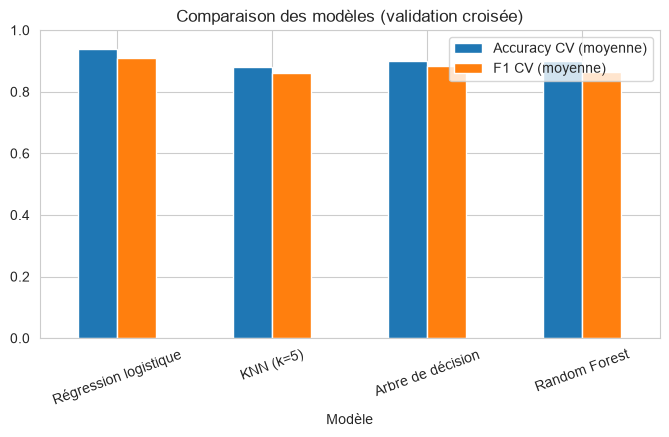

In [20]:
resultats_df.set_index('Modèle')[['Accuracy CV (moyenne)', 'F1 CV (moyenne)']].plot(
    kind='bar', figsize=(8, 4), ylim=(0, 1), title='Comparaison des modèles (validation croisée)')
plt.xticks(rotation=20)
plt.show()

## 4. Interprétation des résultats (30 % de la note)
On détaille deux modèles : la régression logistique (interprétable) et le Random Forest (importance des variables).

              precision    recall  f1-score   support

          No       0.89      1.00      0.94         8
         Yes       1.00      0.86      0.92         7

    accuracy                           0.93        15
   macro avg       0.94      0.93      0.93        15
weighted avg       0.94      0.93      0.93        15



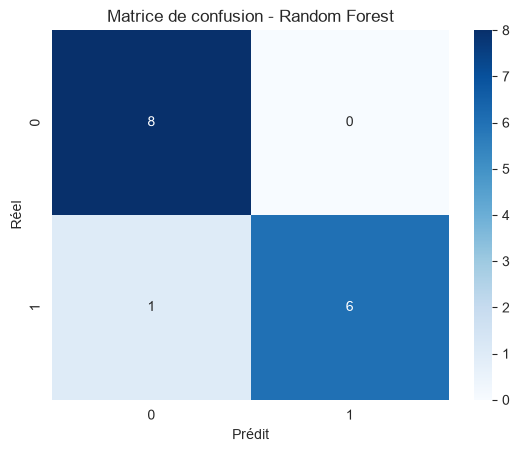

In [21]:
# Détail du Random Forest sur le jeu de test
rf_final = models['Random Forest']
y_pred_final = rf_final.predict(X_test)
print(classification_report(y_test, y_pred_final, target_names=['No', 'Yes']))

sns.heatmap(confusion_matrix(y_test, y_pred_final), annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion - Random Forest')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()

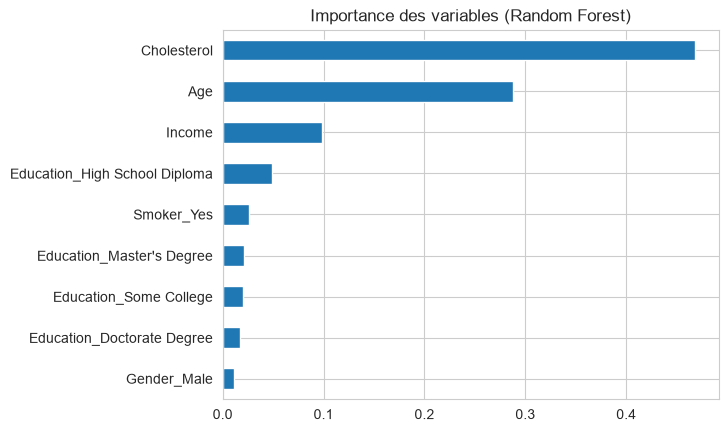

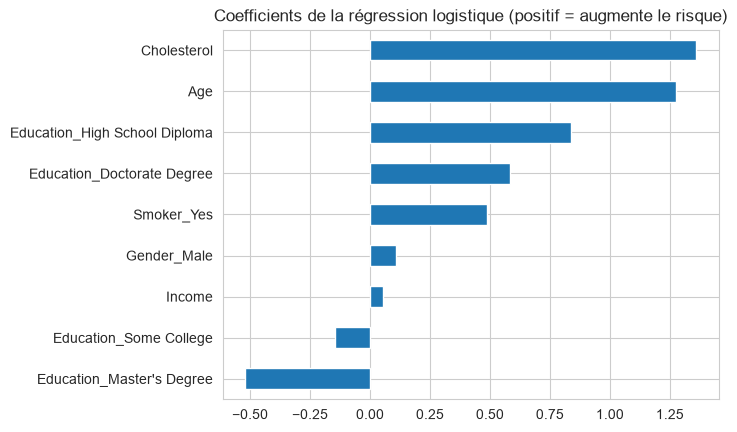

In [22]:
# Importance des variables (Random Forest)
imp = pd.Series(rf_final.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh', title='Importance des variables (Random Forest)')
plt.show()

# Coefficients de la régression logistique (variables standardisées : comparables entre elles)
logreg = models['Régression logistique']
coefs = pd.Series(logreg.named_steps['logisticregression'].coef_[0], index=X.columns).sort_values()
coefs.plot(kind='barh', title='Coefficients de la régression logistique (positif = augmente le risque)')
plt.show()

## 5. Conclusion critique : quel modèle retenir, et pourquoi ?
*(Écris ta conclusion à partir de **tes** résultats. Trame proposée :)*

1. **Résumé des performances** : quel modèle est le meilleur en test simple ? en validation croisée ? Les classements sont-ils identiques ?
2. **Fiabilité** : le dataset ne contient que 50 patients. Un jeu de test de 15 patients rend l'accuracy très instable (un seul patient change le score de ~7 points). Les écarts entre modèles sont-ils plus grands que l'écart-type de la validation croisée ?
3. **Choix du modèle** : en médecine, un **faux négatif** (malade non détecté) est plus grave qu'un faux positif. Quel modèle a le meilleur **rappel** pour la classe « Yes » ?
4. **Interprétabilité** : la régression logistique et l'arbre peu profond sont explicables, utile dans un contexte médical.
5. **Risque de surapprentissage** : le Random Forest peut apprendre « par cœur » un petit dataset.
6. **Limites et pistes** : plus de données, variables cliniques supplémentaires (tension, glycémie...), réglage des hyperparamètres (`GridSearchCV`).

**Modèle retenu : ...** parce que ...